<center><image src="https://drive.google.com/uc?id=1n3G4TdK_u6PQHcLrxB_A0HijNdigXmUH">

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Сегментация изображений</b></h3>


В этом задании вам предстоит решить задачу сегментации медицинских снимков. Домашнее задание можно разделить на следующие части:

* Построй свой первый бейзлайн! [6]
  * BCE Loss [2]
  * SegNet [2]
  * Train [1]
  * Test [1]
* Мир других лоссов! [2]
  * Dice Loss [1]
  * Focal Loss [1]
  * BONUS: лосс из статьи [5]
* Новая модель! [2]
  * UNet [2]


**Максимальный балл:** 10 баллов.

Также для студентов желающих еще более углубиться в задачу предлагается решить бонусное задание, которое даст дополнительные 5 баллов. BONUS задание необязательное.


# Шаг 1. Загрузка и подготовка данных

1. Для начала мы скачаем датасет: [ADDI project](https://www.fc.up.pt/addi/ph2%20database.html).

<table><tr><td>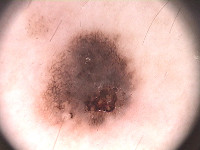</td><td>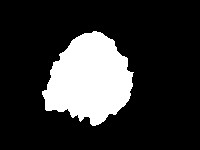</td></tr></table>

2. Разархивируем .rar файл.
3. Обратите внимание, что папка  `PH2 Dataset images` должна лежать там же где и ipynb notebook.

Это фотографии двух типов **поражений кожи:** меланома и родинки.
В данном задании мы не будем заниматься их классификацией, а будем **сегментировать** их.

In [77]:
!gdown 1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql

Downloading...
From (original): https://drive.google.com/uc?id=1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql
From (redirected): https://drive.google.com/uc?id=1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql&confirm=t&uuid=dc075c54-e0f4-41fb-817a-5a03b4455930
To: /content/PH2Dataset.rar
100% 162M/162M [00:02<00:00, 60.0MB/s]


In [78]:
get_ipython().system_raw("unrar x PH2Dataset.rar")

Стуктура датасета у нас следующая:

    IMD_002/
        IMD002_Dermoscopic_Image/
            IMD002.bmp
        IMD002_lesion/
            IMD002_lesion.bmp
        IMD002_roi/
            ...
    IMD_003/
        ...
        ...

 Здесь `X.bmp` — изображение, которое нужно сегментировать, `X_lesion.bmp` — результат сегментации.

Для загрузки датасета можно использовать skimage: [`skimage.io.imread()`](https://scikit-image.org/docs/dev/api/skimage.io.html)

In [79]:
images = []
lesions = []
from skimage.io import imread
import os
root = 'PH2Dataset'

for root, dirs, files in os.walk(os.path.join(root, 'PH2 Dataset images')):
    if root.endswith('_Dermoscopic_Image'):
        images.append(imread(os.path.join(root, files[0])))
    if root.endswith('_lesion'):
        lesions.append(imread(os.path.join(root, files[0])))

Изображения имеют разные размеры. Давайте изменим их размер на $256\times256 $ пикселей. Для изменения размера изображений можно использовать [`skimage.transform.resize()`](https://scikit-image.org/docs/dev/api/skimage.transform.html#skimage.transform.resize).
Эта функция также автоматически нормализует изображения в диапазоне $[0,1]$.


In [80]:
from skimage.transform import resize
size = (256, 256)
X = [resize(x, size, mode='constant', anti_aliasing=True,) for x in images]
Y = [resize(y, size, mode='constant', anti_aliasing=False) > 0.5 for y in lesions]

In [81]:
import numpy as np
X = np.array(X, np.float32)
Y = np.array(Y, np.float32)
print(f'Loaded {len(X)} images')

Loaded 200 images


Чтобы убедиться, что все корректно, мы нарисуем несколько изображений

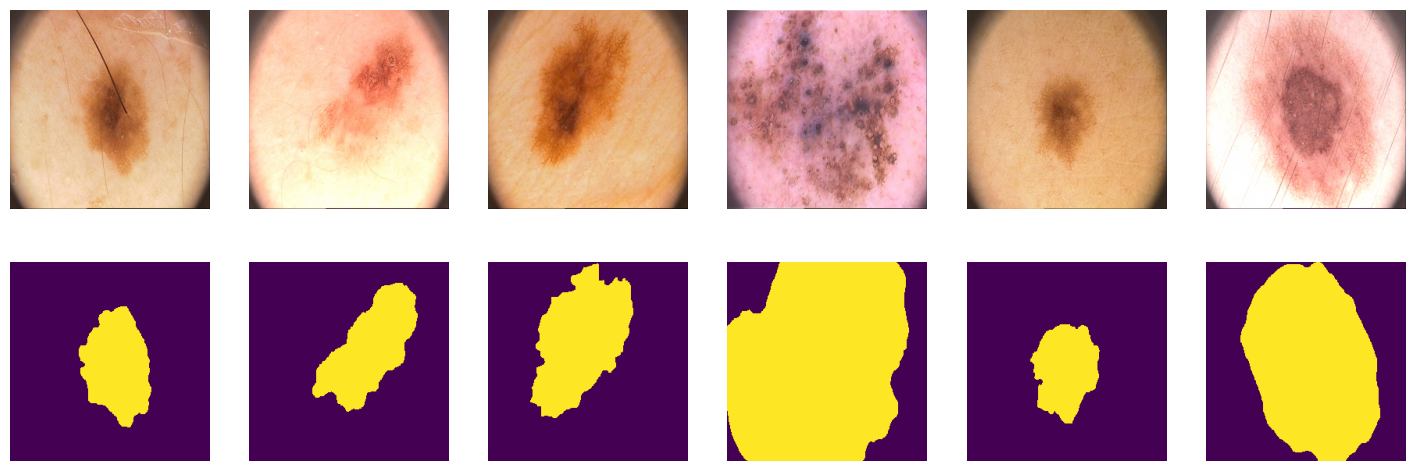

In [82]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

plt.figure(figsize=(18, 6))
for i in range(6):
    plt.subplot(2, 6, i+1)
    plt.axis("off")
    plt.imshow(X[i])

    plt.subplot(2, 6, i+7)
    plt.axis("off")
    plt.imshow(Y[i])
plt.show();

Разделим наши 200 картинок на 100/50/50
 для обучения, валидации и теста соответственно

In [83]:
ix = np.random.choice(len(X), len(X), False)
np.random.seed(42)
tr, val, ts = np.split(ix, [100, 150])

In [84]:
print(len(tr), len(val), len(ts))

100 50 50


## PyTorch DataLoader

In [85]:
from torch.utils.data import DataLoader
batch_size = 25
train_dataloader = DataLoader(list(zip(np.rollaxis(X[tr], 3, 1), Y[tr, np.newaxis])),
                     batch_size=batch_size, shuffle=True)
valid_dataloader = DataLoader(list(zip(np.rollaxis(X[val], 3, 1), Y[val, np.newaxis])),
                      batch_size=batch_size, shuffle=False)
test_dataloader = DataLoader(list(zip(np.rollaxis(X[ts], 3, 1), Y[ts, np.newaxis])),
                     batch_size=batch_size, shuffle=False)

In [86]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Шаг 2. Метрика качества модели

## IoU (intersection over union)

В данном разделе предлагается использовать следующую метрику для оценки качества:

$I o U=\frac{\text {target } \cap \text { prediction }}{\text {target } \cup{prediction }}$

Пересечение (A ∩ B) состоит из пикселей, найденных как в маске предсказания, так и в основной маске истины, тогда как объединение (A ∪ B) просто состоит из всех пикселей, найденных либо в маске предсказания, либо в целевой маске.


Что будет являться пересением и объединением в задаче сегментации?

Давайте разберем следующий пример:





<p style="align: center;"><img align=center src="https://drive.google.com/uc?export=view&id=1rBYFgli48AUUN9idiyq8j3J5DboB93yN" width=1000 height=800/></p>

In [87]:
!pip install torchmetrics

In [88]:
from torchmetrics import JaccardIndex

iou_score = JaccardIndex(threshold=0.5, task="binary", average='none').to(device)

# Задания: Построй свой первый бейзлайн!

Итак, загрузка файлов, код датасета и даталоадера написана за вас. Метрика IoU написана за вас! Вам остается написать лосс, модель и функции обучения и теста модели.

* Построй свой первый бейзлайн! [6]
  * BCE Loss [2]
  * SegNet [2]
  * Train [1]
  * Test [1]

## Шаг 3. Loss функция - BCE [2 балла]

Популярным лоссом для бинарной сегментации является *бинарная кросс-энтропия*, которая задается следующим образом:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right] \space [1]$$

где $y$ это  таргет желаемого результата и $\hat y$ является выходом модели. $\sigma$ - это [*логистическая* функция](https://en.wikipedia.org/wiki/Sigmoid_function), который преобразует действительное число $\mathbb R$ в вероятность $[0,1]$.

Однако эта потеря страдает от проблем численной нестабильности. Самое главное, что $\lim_{x\rightarrow 0^+}\log(x)=-\infty$ приводит к неустойчивости в процессе оптимизации. Рекомендуется посмотреть следующее [упрощение](https://www.tensorflow.org/api_docs/python/tf/nn/sigmoid_cross_entropy_with_logits). Эта функция эквивалентна первой и не так подвержена численной неустойчивости:

$$\mathcal L_{BCE} = \hat y^T \mathbf{1} - y^T \hat y + \mathbf{1}^T \log\left(1+\exp(-\hat y)\right) \space [2]$$

### Вывод численно стабильной формулы BCE лосса [1 балл]



Выведите из формулы [1] формулу [2]:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right] \space [1]$$

$$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right) \space [2]$$

Не забываем, что здесь $\hat y_i$ - это логиты сети, не вероятности и не лейблы.


### Ответ

Начальная формула для одного элемента:

$$
L = -[y\log(\sigma(\hat y))+(1-y)\log(1-\sigma(\hat y))]
$$

По определению сигмоиды:

$$
\sigma(\hat y)=\frac{1}{1+e^{-\hat y}}
$$

Следовательно:

$$
\log(\sigma(\hat y))=-\log(1+e^{-\hat y})
$$

$$
\log(1-\sigma(\hat y))=-\hat y-\log(1+e^{-\hat y})
$$

Подставляем в исходную формулу:

$$
L=y\log(1+e^{-\hat y})+(1-y)(\hat y+\log(1+e^{-\hat y}))
$$

Раскрываем скобки:

$$
L=y\log(1+e^{-\hat y})+\hat y-y\hat y+(1-y)\log(1+e^{-\hat y})
$$

Объединяем логарифмы:

$$
L=(y+1-y)\log(1+e^{-\hat y})+\hat y-y\hat y
$$

Получаем формулу [2]:

$$
\boxed{L=\hat y-y\hat y+\log(1+\exp(-\hat y))}
$$


### Реализуйте в коде оба варианта лосса [1 балл]

Реализуйте следующие функции:

*   `bce_true()` - честная прямая реализация лосса с формулой $$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$
*   `bce_loss()` - реализация формулы, которую мы вывели $$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right).$$

И сравните результаты функций с реализацией Pytorch:
*   `bce_torch()`
*   `bce_torch_with_logits()`

In [89]:
import torch.nn.functional as F
import torch.nn as nn

In [90]:
bce_torch = nn.BCELoss(reduction='sum') # (sigmoid(y_pred), y_real)
bce_torch_with_logits = nn.BCEWithLogitsLoss(reduction='sum')

In [91]:
# Формула 2
def bce_loss(y_pred, y_real):
    return torch.sum(
        y_pred - y_real * y_pred + torch.log(1 + torch.exp(-y_pred))
    )

# Формула 1
def bce_true(y_pred, y_real):
    y_pred = torch.sigmoid(y_pred)

    return -torch.sum(
        y_real * torch.log(y_pred)
        + (1 - y_real) * torch.log(1 - y_pred)
    )


Проверим корректность работы на простом примере

In [92]:
y_pred = torch.randn(3, 2, requires_grad=False)
y_true = torch.rand(3, 2, requires_grad=False)

print(f'BCE loss from scratch bce_loss             = {bce_loss(y_pred, y_true)}')
print(f'BCE loss честно посчитанный                = {bce_true(y_pred, y_true)}')
print(f'BCE loss from torch bce_torch              = {bce_torch(torch.sigmoid(y_pred), y_true)}')
print(f'BCE loss from torch with logits bce_torch  = {bce_torch_with_logits(y_pred, y_true)}')


BCE loss from scratch bce_loss             = 4.820694446563721
BCE loss честно посчитанный                = 4.820694446563721
BCE loss from torch bce_torch              = 4.820694446563721
BCE loss from torch with logits bce_torch  = 4.820694446563721


Инструкции `assert` в Python — это булевы выражения, которые проверяют, является ли условие истинным (`True`). Внизу в коде мы проверяем функция `bce_loss()` выдает тот же результат, что и функция из Pytorch или нет. Если равенства не будет, что будет означать, что результаты функций не совпадают, а значит вы неправильно реализовали фукнцию `bce_loss()`, `assert` возвратит ошибку.

Функция `numpy.isclose()` используется для сравнения двух чисел с учётом допустимой погрешности. Она особенно полезна при работе с числами с плавающей точкой, где точное сравнение может быть проблематичным из-за ограничений представления таких чисел в компьютере.

Как она работает?

`numpy.isclose(a, b, rtol=1e-05, atol=1e-08) `принимает два числа (`a` и `b`) и сравнивает их, учитывая относительную и абсолютную погрешность. Если разница между двумя числами меньше заданного порога, функция возвращает `True`, иначе — `False`.

Параметры:

    rtol: Относительная погрешность (по умолчанию 1e-05). Используется для определения разницы относительно большего значения.
    atol: Абсолютная погрешность (по умолчанию 1e-08). Определяет минимальную разницу, которую следует учитывать.

Мы будем использовать `assert` и `numpy.isclose()` для проверки корректности нашего кода.

In [93]:
assert np.isclose(bce_loss(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true))
assert np.isclose(bce_loss(y_pred, y_true), bce_torch_with_logits(y_pred, y_true))
assert np.isclose(bce_true(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true))
assert np.isclose(bce_true(y_pred, y_true), bce_torch_with_logits(y_pred, y_true))

Давайте теперь посчитаем на простом примере, но с теми же размерностями, что и в датасете

In [94]:
y_pred = torch.randn((2, 1, 3, 3), requires_grad=False)
y_true = torch.randint(0, 2, (2, 1, 3, 3))

print(f'BCE loss from scratch bce_loss            = {bce_loss(y_pred, y_true)}')
print(f'BCE loss честно посчитанный               = {bce_true(y_pred, y_true)}')
print(f'BCE loss from torch bce_torch             = {bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float))}')
print(f'BCE loss from torch with logits bce_torch = {bce_torch_with_logits(y_pred, y_true.to(torch.float))}')

BCE loss from scratch bce_loss            = 15.669721603393555
BCE loss честно посчитанный               = 15.669721603393555
BCE loss from torch bce_torch             = 15.669721603393555
BCE loss from torch with logits bce_torch = 15.669721603393555


In [95]:
assert np.isclose(bce_loss(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float)))
assert np.isclose(bce_loss(y_pred, y_true), bce_torch_with_logits(y_pred, y_true.to(torch.float)))
assert np.isclose(bce_true(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float)))
assert np.isclose(bce_true(y_pred, y_true), bce_torch_with_logits(y_pred, y_true.to(torch.float)))

Давайте посчитаем на реальных логитах и сегментационной маске:

In [96]:
!gdown --folder 1EX0RW1TRQVkLmR1h6miCQqyhYPFyg28M

Retrieving folder contents
Processing file 1--WxvBdpMn_NOmYPf3a4au8MHzfx5baC labels.pt
Processing file 1-0A7_CS_vKiSCkgIDJ4joThCEcFedA3I logits.pt
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1--WxvBdpMn_NOmYPf3a4au8MHzfx5baC
To: /content/for_asserts/labels.pt
100% 1.18k/1.18k [00:00<00:00, 4.32MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-0A7_CS_vKiSCkgIDJ4joThCEcFedA3I
To: /content/for_asserts/logits.pt
100% 1.18k/1.18k [00:00<00:00, 5.35MB/s]
Download completed


In [97]:
path_to_dummy_samples = '/content/for_asserts'
dummpy_sample = {'logits': torch.load(f'{path_to_dummy_samples}/logits.pt'),
                 'labels': torch.load(f'{path_to_dummy_samples}/labels.pt')}
dummpy_sample['labels'] = dummpy_sample['labels'].to(device)
dummpy_sample['logits'] = dummpy_sample['logits'].to(device)

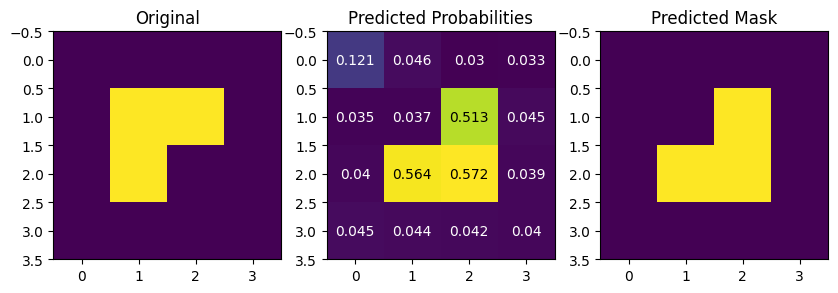

In [98]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize= (10,3*10))

ax1.imshow(dummpy_sample['labels'].squeeze(1)[0].cpu())
ax1.set_title("Original")

ax2.imshow(dummpy_sample['logits'].sigmoid().squeeze(1)[0].cpu())
for (j,i),label in np.ndenumerate(dummpy_sample['logits'].sigmoid().squeeze(1)[0].cpu()):
    if label < 0.5:
        color = 'white'
    else:
        color = 'black'
    ax2.text(i,j,round(label,3), color=color, ha='center',va='center')

ax2.set_title("Predicted Probabilities")

ax3.imshow((dummpy_sample['logits'].sigmoid() > 0.5).squeeze(1)[0].cpu())
ax3.set_title("Predicted Mask")
plt.show()

Проверяем на данном примере:

In [99]:
bce_loss_score = bce_loss(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu())
bce_true_score = bce_true(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu())
bce_torch_score = bce_torch(torch.sigmoid(dummpy_sample['logits'].cpu()), dummpy_sample['labels'].cpu().float())
bce_torch_with_logits_score = bce_torch_with_logits(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu().float())
assert np.isclose(bce_loss_score, bce_torch_score)
assert np.isclose(bce_loss_score, bce_torch_with_logits_score)
assert np.isclose(bce_true_score, bce_torch_score)
assert np.isclose(bce_true_score, bce_torch_with_logits_score)

## Шаг 4. Модель SegNet [2 балла]

Ваше задание здесь состоит в том, чтобы реализовать SegNet архитектуру.

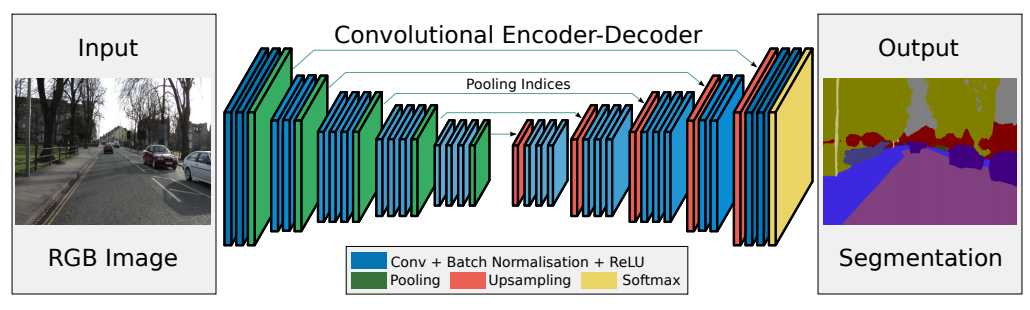

* Badrinarayanan, V., Kendall, A., & Cipolla, R. (2015). [SegNet: A deep convolutional
encoder-decoder architecture for image segmentation](https://arxiv.org/pdf/1511.00561.pdf)

In [100]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
import torch.optim as optim
from time import time

from matplotlib import rcParams
rcParams['figure.figsize'] = (15,4)

Внимательно посмотрите из чего состоит модель и для чего выбраны те или иные блоки. Для этого скачаем и изучим feature extractor VGG-16, который лежит в основе SegNet.

In [101]:
model_vgg16 = models.vgg16(weights = models.VGG16_Weights.IMAGENET1K_V1)

In [102]:
model_vgg16

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

Feature extractor VGG-16 состоит из 5 блоков:
- два блока со структурой:
Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d
- три блока со структурой:
Conv2d -> ReLU -> Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d

В первом блоке - на входе три канала (по числу каналов в изображениях), которые конволюционный слой преобразует в 64 канала.

Во втором, третьем и четвертом блоках первый конволюционный слой удваивает количество каналов, а последующие конволюционные слои не меняют количество каналов.

В последнем блоке число каналов от слоя к слою не меняется.

Теперь напишем код одного блока энкодера нашей модели SegNet.  

In [103]:
# Параметрами блока будут:
# - количество каналов на входе
# - количество каналов на выходе
# - глубина блока (2 или 3, по количеству конволюционных слоев)
# - kernel_size и padding
#
class EncoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, depth, kernel_size = 3, padding = 1):
        super(EncoderBlock, self).__init__() # инициируем экземляр класса, наследующего от nn.Module
        self.layers = nn.ModuleList() # в self.layers будем добавлять слои блока
        # дальше реализуем то, что на картинке выше обозначено Conv + Batch Normalization + ReLU
        self.layers.append(nn.Conv2d(in_channels = in_channels, out_channels = out_channels, kernel_size = kernel_size, padding = padding))
        self.layers.append(nn.BatchNorm2d(out_channels))
        self.layers.append(nn.ReLU(inplace=True))

        # цикл for помогает использовать один код для блоков как с глубиной 2, так и с глубиной 3
        for i in range(depth-1):
            self.layers.append(nn.Conv2d(in_channels = out_channels, out_channels = out_channels, kernel_size = kernel_size, padding = padding))
            self.layers.append(nn.BatchNorm2d(out_channels))
            self.layers.append(nn.ReLU(inplace=True))

        self.maxpooling = nn.MaxPool2d(kernel_size=2, stride=2, return_indices=True) #добавляем MaxPool с индексами для последующего Unpooling

    # Обратите внимание: на вход метод forward() получает карту признаков (х),
    # а возвращает карту признаков и индексы для последующего Unpooling
    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        x, indices = self.maxpooling(x)
        return x, indices


По аналогии напишите код одного блока декодера.

К карте признаков на входе каждого блока примеяется nn.MaxUnpool2d с индексами из симметричного блока энкодера. Затем повторяется связка Conv + Batch Normalization + ReLU. Количество каналов меняется зеркально блокам энкодера:
- в первом блоке декодера количество каналов не меняется
- во 2-4 блоках декодера количество каналов уменьшается в 2 раза после прохождения последнего конволюционного слоя
- на выходе из последнего блока декодера 1 канал

Обратите внимание, что после последней конволюции последнего блока декодера не применяется батч-нормализация и функция активации.

In [104]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, depth,
                 kernel_size=3, padding=1, last_block=False):
        super(DecoderBlock, self).__init__()

        self.layers = nn.ModuleList()

        for i in range(depth - 1):
            self.layers.append(nn.Conv2d(in_channels, in_channels,
                                         kernel_size, padding=padding))
            self.layers.append(nn.BatchNorm2d(in_channels))
            self.layers.append(nn.ReLU(inplace=True))

        self.layers.append(nn.Conv2d(in_channels, out_channels,
                                     kernel_size, padding=padding))

        if not last_block:
            self.layers.append(nn.BatchNorm2d(out_channels))
            self.layers.append(nn.ReLU(inplace=True))

        self.unpooling = nn.MaxUnpool2d(kernel_size=2, stride=2)

    def forward(self, x, indices):
        x = self.unpooling(x, indices)

        for layer in self.layers:
            x = layer(x)

        return x


Соединим блоки энкодера и декодера в модель SegNet:

In [105]:

class SegNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, num_features=64) -> None:
        super(SegNet, self).__init__()

        # Encoder
        self.encoder0 = EncoderBlock(in_channels, num_features, depth=2)
        self.encoder1 = EncoderBlock(num_features, num_features * 2, depth=2)
        self.encoder2 = EncoderBlock(num_features * 2, num_features * 4, depth=3)
        self.encoder3 = EncoderBlock(num_features * 4, num_features * 8, depth=3)

        # Encoder bottleneck
        self.encoder4 = EncoderBlock(num_features * 8, num_features * 8, depth=3)

        # Decoder bottleneck
        self.decoder0 = DecoderBlock(num_features * 8, num_features * 8, depth=3)

        # Decoder
        self.decoder1 = DecoderBlock(num_features * 8, num_features * 4, depth=3)
        self.decoder2 = DecoderBlock(num_features * 4, num_features * 2, depth=3)
        self.decoder3 = DecoderBlock(num_features * 2, num_features, depth=2)
        self.decoder4 = DecoderBlock(num_features, out_channels, depth=2, last_block=True)

    def forward(self, x):
        # Encoder
        x, indices0 = self.encoder0(x)
        x, indices1 = self.encoder1(x)
        x, indices2 = self.encoder2(x)
        x, indices3 = self.encoder3(x)
        x, indices4 = self.encoder4(x)

        # Decoder
        x = self.decoder0(x, indices4)
        x = self.decoder1(x, indices3)
        x = self.decoder2(x, indices2)
        x = self.decoder3(x, indices1)
        output = self.decoder4(x, indices0)

        return output  # no activation


## Шаг 5. Тренировка модели [1 балл]

Напишите функции для обучения модели.

In [106]:
from tqdm.notebook import tqdm

In [107]:

def train_one_epoch(model, dataloader, optimizer, loss_fn):
    model.train()
    total_loss = 0

    for images, masks in dataloader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = loss_fn(logits, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(dataloader.dataset)


@torch.no_grad()
def eval_one_epoch(model, dataloader, loss_fn):
    model.eval()
    total_loss = 0
    iou_score.reset()

    for images, masks in dataloader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        loss = loss_fn(logits, masks)

        total_loss += loss.item() * images.size(0)
        iou_score.update(torch.sigmoid(logits), masks.int())

    return total_loss / len(dataloader.dataset), iou_score.compute().item()


In [108]:

def train(model, train_dataloader, valid_dataloader, optimizer, loss_fn, epochs=15):
    best_iou = -1

    for epoch in tqdm(range(epochs)):
        train_loss = train_one_epoch(
            model, train_dataloader, optimizer, loss_fn
        )

        valid_loss, valid_iou = eval_one_epoch(
            model, valid_dataloader, loss_fn
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Valid Loss: {valid_loss:.4f} | "
            f"Valid IoU: {valid_iou:.4f}"
        )

        if valid_iou > best_iou:
            best_iou = valid_iou
            torch.save(model.state_dict(), "best_segnet.pth")

    print(f"Best IoU: {best_iou:.4f}")


Обучите модель **SegNet**. В качестве оптимайзера можно взять Adam.

In [109]:

model = SegNet().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()

train(model, train_dataloader, valid_dataloader, optimizer, loss_fn, epochs=15)


  0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.6325 | Valid Loss: 0.6815 | Valid IoU: 0.0000
Epoch 2/15 | Train Loss: 0.5864 | Valid Loss: 0.6407 | Valid IoU: 0.2216
Epoch 3/15 | Train Loss: 0.4385 | Valid Loss: 0.7075 | Valid IoU: 0.2508
Epoch 4/15 | Train Loss: 0.3331 | Valid Loss: 1.4474 | Valid IoU: 0.1851
Epoch 5/15 | Train Loss: 0.2950 | Valid Loss: 0.8087 | Valid IoU: 0.2442
Epoch 6/15 | Train Loss: 0.2391 | Valid Loss: 1.3983 | Valid IoU: 0.2380
Epoch 7/15 | Train Loss: 0.2463 | Valid Loss: 0.8598 | Valid IoU: 0.2901
Epoch 8/15 | Train Loss: 0.2297 | Valid Loss: 0.6569 | Valid IoU: 0.3847
Epoch 9/15 | Train Loss: 0.1959 | Valid Loss: 0.5156 | Valid IoU: 0.4803
Epoch 10/15 | Train Loss: 0.2077 | Valid Loss: 0.5297 | Valid IoU: 0.5293
Epoch 11/15 | Train Loss: 0.1805 | Valid Loss: 0.4379 | Valid IoU: 0.5975
Epoch 12/15 | Train Loss: 0.1678 | Valid Loss: 0.3528 | Valid IoU: 0.6795
Epoch 13/15 | Train Loss: 0.1614 | Valid Loss: 0.3319 | Valid IoU: 0.6834
Epoch 14/15 | Train Loss: 0.1680 | Valid Loss: 

## Шаг 6. Инференс [1 балл]

После обучения модели напишите функцию теста, воспользуйтесь лучшим чекпоинтом и протестируйте работу модели на тестовой выборке.

In [110]:

@torch.no_grad()
def test(model, dataloader, loss_fn):
    model.eval()
    iou_score.reset()
    total_loss = 0

    for images, masks in tqdm(dataloader):
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        loss = loss_fn(logits, masks)

        total_loss += loss.item() * images.size(0)
        iou_score.update(torch.sigmoid(logits), masks.int())

    test_loss = total_loss / len(dataloader.dataset)
    test_iou = iou_score.compute().item()

    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test IoU: {test_iou:.4f}")

    return test_loss, test_iou


In [111]:

from pathlib import Path

assert Path("best_segnet.pth").exists(), "Чекпоинт не найден"

model = SegNet().to(device)
model.load_state_dict(
    torch.load("best_segnet.pth", map_location=device, weights_only=True)
)

test_loss, test_iou = test(
    model, test_dataloader, nn.BCEWithLogitsLoss()
)


  0%|          | 0/2 [00:00<?, ?it/s]

Test Loss: 0.2513
Test IoU: 0.7405


# Задания: Мир других лоссов!

## Пробуем другие функции потерь [2 балла]

В данном разделе вам потребуется имплементировать две функции потерь: DICE и Focal loss.


### Dice Loss

**1. Dice coefficient:** Учитывая две маски $X$ и $Y$, общая метрика для измерения расстояния между этими двумя масками задается следующим образом:

$$D(X,Y)=\frac{2|X\cap Y|}{|X|+|Y|}$$

В терминах матрицы ошибок она будет считаться следующим образом:

$$D(X,Y) = \frac{2TP}{2TP + FP + FN}$$

Эта функция не является дифференцируемой, но это необходимое свойство для градиентного спуска. В данном случае мы можем приблизить его с помощью:

$$\mathcal L_D(X,Y) = 1- D(X, Y)$$

**Hints** (!):

1. Не забудьте подумать о численной нестабильности, возникающей в математической формуле при ситуации, когда $\frac{0}{0}$, т.е. вам нужно добавить очень маленькое число, например $\epsilon = 1e^{-8}$, в обе части дроби при подсчете $D(X,Y)$:

$$D(X,Y) = \frac{2TP + ϵ}{2TP + FP + FN + ϵ}$$

2. Dice метрика(!), не лосс, считается похожим образом как IoU:

    2.1. На вход вам приходят logits, т.е. значения от $-∞$ до $∞$. Их переводим в вероятности от 0 до 1 при помощи функции Sigmoid.

    2.2. Фиксируем порог, например threshold=0.5, и всему что ниже порога ставим значение 0, всему что выше 1. Получаем предсказанную маску из 0 и 1.

    2.3. Считаем TP, FP, FN

    2.4. Считаем DICE метрику по формуле

Вы можете прописать для себя функцию `dice_score()` и сравнить с результатами работы функции из библиотеки `torchmetrics`.

3. Но с метрикой есть проблема, что она не дифференцируема, и если вы захотите просто взять и прописать `dice_loss` = 1 - `dice_score`, Pytorch поругается на вас и скажет, что это недифференцируемая метрика. Чтобы посчитать dice_loss делаем следующие шаги:

    3.1. На вход вам приходят logits, т.е. значения от $-∞$ до $∞$. Их переводим в вероятности от 0 до 1 при помощи функции Sigmoid.

    3.2. Здесь нам уже не нужно фиксировать порог, мы просто работаем с вероятностями. Значения вероятностей дифференцируемы и через них будут протекать градиенты.

    3.3. Считаем TP, FP, FN также как и в Dice метрике, только вместо маски, подаем вероятности.

    3.4. Считаем DICE метрику по формуле

    3.5. Считаем лосс как Loss = 1 - DICE

Итак, давайте сначала пропишем dice_score.

In [112]:

def dice_score(logits: torch.Tensor, labels: torch.Tensor, threshold: float = 0.5):
    probs = torch.sigmoid(logits)

    preds = (probs >= threshold).float()
    labels = labels.float()

    tp = (preds * labels).sum()
    fp = (preds * (1 - labels)).sum()
    fn = ((1 - preds) * labels).sum()

    eps = 1e-8
    score = (2 * tp + eps) / (2 * tp + fp + fn + eps)

    return score


Проверим на корректность функцию dice_score:

In [113]:

from torchmetrics.classification import BinaryF1Score

# Заменили DiceScore на BinaryF1Score, так как он корректно
# обрабатывает вероятности с порогом 0.5 для бинарной сегментации.
dice = BinaryF1Score(threshold=0.5).to(device)

dice(dummpy_sample['logits'].sigmoid(),dummpy_sample['labels'].int())


tensor(0.6667, device='cuda:0')

In [114]:
'''
если вы используете версию библиотеки 0.11.4, то можно взять torchmetrics.classification.Dice():

from torchmetrics.classification import Dice

dice = Dice(average='micro').to(device)

'''

"\nесли вы используете версию библиотеки 0.11.4, то можно взять torchmetrics.classification.Dice():\n\nfrom torchmetrics.classification import Dice\n\ndice = Dice(average='micro').to(device)\n\n"

In [115]:
assert dice(dummpy_sample['logits'].sigmoid(), dummpy_sample['labels'].to(int)) == dice_score(dummpy_sample['logits'], dummpy_sample['labels'])

Давайте теперь пропишем лосс и воспользуемся библиотекой `segmentation-models-pytorch`, чтобы убедиться в корректности нашей функции.

In [116]:
def dice_loss(logits: torch.Tensor, labels: torch.Tensor):
    probs = torch.sigmoid(logits)
    labels = labels.float()

    tp = (probs * labels).sum()
    fp = (probs * (1 - labels)).sum()
    fn = ((1 - probs) * labels).sum()

    eps = 1e-8
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)

    loss = 1 - dice
    return loss


Проверка на корректность:

In [117]:
# проверьте, что у вас установлена библиотека
!pip install segmentation-models-pytorch

In [118]:
from segmentation_models_pytorch.losses import DiceLoss
dice_loss_torch = DiceLoss(mode='binary')
dice_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'])

tensor(0.5756, device='cuda:0')

In [119]:
assert dice_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'].to(int)) == dice_loss(dummpy_sample['logits'], dummpy_sample['labels'])

### Focal Loss

[**2. Focal loss:**](https://arxiv.org/pdf/1708.02002.pdf)

Окей, мы уже с вами умеем делать BCE loss:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

Проблема с этой потерей заключается в том, что она имеет тенденцию приносить пользу классу **большинства** (фоновому) по отношению к классу **меньшинства** ( переднему). Поэтому обычно применяются весовые коэффициенты к каждому классу:

$$\mathcal L_{wBCE}(y, \hat y) = -\sum_i \alpha_i\left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

Традиционно вес $\alpha_i$ определяется как обратная частота класса этого пикселя $i$, так что наблюдения миноритарного класса весят больше по отношению к классу большинства.


Из оригинальной статьи по [Focal Loss](https://arxiv.org/pdf/1708.02002.pdf):

$$p_t = \sigma(\hat y_i)y_i + (1 - \sigma(\hat y_i)) (1-y_i)$$

$$\mathcal L_{focal}(y, \hat y) = (1 - p_t)^{\gamma} \mathcal L_{BCE}(y_i, \hat y_i).$$

$$\mathcal L_{focal}(y, \hat y) = -\sum_i (1 - p_t)^{\gamma} \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

$$\mathcal L_{focal}(y, \hat y) = -\sum_i (1 - (\sigma(\hat y_i)y_i + (1 - \sigma(\hat y_i)) (1-y_i)))^{\gamma} \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

In [120]:
def focal_loss(y_real, y_pred, eps=1e-8, gamma=2):
    probs = torch.sigmoid(y_pred)

    bce = F.binary_cross_entropy_with_logits(
        y_pred, y_real, reduction='none'
    )

    pt = probs * y_real + (1 - probs) * (1 - y_real)

    loss = bce * ((1 - pt) ** gamma)

    return loss.sum()


Проверка корректности функции:

In [121]:
from torchvision.ops import sigmoid_focal_loss
sigmoid_focal_loss(dummpy_sample['logits'], dummpy_sample['labels'], alpha=-1, gamma=2, reduction='sum')

tensor(3.6161, device='cuda:0')

In [122]:
assert sigmoid_focal_loss(dummpy_sample['logits'], dummpy_sample['labels'], alpha=-1, gamma=2, reduction='sum') == focal_loss(dummpy_sample['labels'], dummpy_sample['logits'], gamma=2.0)

## [BONUS] Мир сегментационных лоссов [5 баллов]

В данном блоке предлагаем вам написать одну функцию потерь самостоятельно. Для этого необходимо прочитать статью и имплементировать ее, и провести численное сравнение с предыдущими функциями.
 **ВАЖНО:** за имплементацию одного лосса выдается только один балл. Чтобы получить все 5 баллов, будет необходимо имплементировать все 5 лоссов.

* [Physiological Inspired Deep Neural Networks for Emotion Recognition](https://ieeexplore.ieee.org/stamp/stamp.jsp?arnumber=8472816&tag=1)". IEEE Access, 6, 53930-53943.

* [Boundary loss for highly unbalanced segmentation](https://arxiv.org/abs/1812.07032)

* [Tversky loss function for image segmentation using 3D fully convolutional deep networks](https://arxiv.org/abs/1706.05721)

* [Correlation Maximized Structural Similarity Loss for Semantic Segmentation](https://arxiv.org/abs/1910.08711)

* [Topology-Preserving Deep Image Segmentation](https://papers.nips.cc/paper/8803-topology-preserving-deep-image-segmentation)

In [123]:
import torch
import torch.nn.functional as F
import numpy as np

from scipy.ndimage import distance_transform_edt


Physiological Inspired Deep Neural Networks for Emotion Recognition


In [124]:
def physiological_loss(logits, labels, lam=0.1, gamma=0.1):
    probs = torch.sigmoid(logits)
    labels = labels.float()

    bce = F.binary_cross_entropy_with_logits(logits, labels)

    sparsity = probs.abs().mean()

    dh = (probs[:, :, 1:, :] - probs[:, :, :-1, :]).abs().mean()
    dw = (probs[:, :, :, 1:] - probs[:, :, :, :-1]).abs().mean()

    smoothness = dh + dw

    return bce + lam * (sparsity + gamma * smoothness)


Boundary Loss

In [125]:
def signed_distance_map(labels):
    masks = labels.detach().cpu().numpy() > 0.5
    distances = np.zeros_like(masks, dtype=np.float32)

    for b in range(masks.shape[0]):
        for c in range(masks.shape[1]):
            mask = masks[b, c]

            if mask.any() and (~mask).any():
                outside = distance_transform_edt(~mask) * (~mask)
                inside = (distance_transform_edt(mask) - 1) * mask

                distances[b, c] = outside - inside

    return torch.as_tensor(
        distances, device=labels.device, dtype=labels.dtype
    )



def generalized_dice_loss(logits, labels, eps=1e-8):
    probs = torch.sigmoid(logits)
    labels = labels.float()

    dims = (1, 2, 3)

    fg = labels.sum(dim=dims)
    bg = (1 - labels).sum(dim=dims)

    w_fg = torch.where(
        fg > 0, 1 / fg.clamp_min(1).square(), 0
    )
    w_bg = torch.where(
        bg > 0, 1 / bg.clamp_min(1).square(), 0
    )

    intersection_fg = (probs * labels).sum(dim=dims)
    intersection_bg = ((1 - probs) * (1 - labels)).sum(dim=dims)

    numerator = 2 * (
        w_fg * intersection_fg + w_bg * intersection_bg
    )

    denominator = (
        w_fg * (probs + labels).sum(dim=dims)
        + w_bg * (2 - probs - labels).sum(dim=dims)
    )

    return (1 - (numerator + eps) / (denominator + eps)).mean()


def boundary_loss(logits, labels, alpha=0.99):
    probs = torch.sigmoid(logits)
    distances = signed_distance_map(labels.float())

    boundary = (probs * distances).mean()
    gdl = generalized_dice_loss(logits, labels)

    return alpha * gdl + (1 - alpha) * boundary



Tversky Loss

In [126]:
def tversky_loss(logits, labels, alpha=0.3, beta=0.7, eps=1e-8):
    probs = torch.sigmoid(logits)
    labels = labels.float()

    dims = (1, 2, 3)

    tp = (probs * labels).sum(dim=dims)
    fp = (probs * (1 - labels)).sum(dim=dims)
    fn = ((1 - probs) * labels).sum(dim=dims)

    tversky = (tp + eps) / (
        tp + alpha * fp + beta * fn + eps
    )

    return 1 - tversky.mean()


Structural Similarity Loss

In [127]:
def structural_similarity_loss(
    logits, labels, window_size=3, sigma=1.5,
    beta=0.1, lam=0.5, c4=0.01
):
    labels = labels.float()
    probs = torch.sigmoid(logits)

    channels = probs.shape[1]
    radius = window_size // 2

    x = torch.arange(
        window_size, device=logits.device, dtype=logits.dtype
    ) - radius

    g = torch.exp(-0.5 * (x / sigma) ** 2)
    g = g / g.sum()

    kernel_2d = torch.outer(g, g)
    kernel = kernel_2d[None, None].expand(
        channels, 1, -1, -1
    ).contiguous()

    def local_stats(t):
        padded = F.pad(t, (radius,) * 4, mode='reflect')

        mean = F.conv2d(padded, kernel, groups=channels)
        mean_sq = F.conv2d(
            padded.square(), kernel, groups=channels
        )

        std = (mean_sq - mean.square()).clamp_min(0).sqrt()
        return mean, std

    mean_y, std_y = local_stats(labels)
    mean_p, std_p = local_stats(probs)

    error = torch.abs(
        (labels - mean_y + c4) / (std_y + c4)
        - (probs - mean_p + c4) / (std_p + c4)
    )

    center = kernel_2d[radius, radius]
    e_max = 2 * (1 - center) / (
        torch.sqrt(center * (1 - center)) + c4
    )

    hard = (error > beta * e_max).float()

    weights = error.detach() * hard

    bce = F.binary_cross_entropy_with_logits(
        logits, labels, reduction='none'
    )

    ssl = (weights * bce).sum() / hard.sum().clamp_min(1)

    return lam * bce.mean() + (1 - lam) * ssl


Topological Loss

In [128]:
!pip install gudhi

In [129]:
import gudhi

def persistence_pairs(image):
    values = 1 - image.detach().cpu().numpy()

    complex_ = gudhi.CubicalComplex(
        top_dimensional_cells=values
    )
    complex_.persistence(
        homology_coeff_field=2, min_persistence=0
    )

    finite, essential = complex_.cofaces_of_persistence_pairs()
    flat = values.ravel()

    result = []

    for dim in (0, 1):
        pairs = finite[dim] if dim < len(finite) else []
        features = []

        for birth, death in pairs:
            b = float(flat[birth])
            d = float(flat[death])

            if d > b:
                features.append((int(birth), int(death), b, d))

        result.append(features)

    essential_h0 = (
        essential[0] if len(essential) > 0 else []
    )

    return result, essential_h0


def topological_term(logits, labels, patch_size=64,
                     min_persistence=0.03):
    probs = torch.sigmoid(logits)
    labels = labels.float()

    assert probs.ndim == 4 and probs.shape[1] == 1

    total = probs.sum() * 0.0
    count = 0

    for batch in range(probs.shape[0]):
        h, w = probs.shape[-2:]

        for y in range(0, h, patch_size):
            for x in range(0, w, patch_size):
                pred = probs[
                    batch, 0, y:y + patch_size, x:x + patch_size
                ]
                gt = labels[
                    batch, 0, y:y + patch_size, x:x + patch_size
                ]

                pred_pairs, pred_essential = persistence_pairs(pred)
                gt_pairs, _ = persistence_pairs(gt)

                flat = pred.reshape(-1)

                if gt.max().item() > 0.5 and len(pred_essential):
                    birth = int(pred_essential[0])
                    total = total + (1 - flat[birth]).square()
                    count += 1

                for dim in (0, 1):
                    target_count = sum(
                        (d - b) > 0.5
                        for _, _, b, d in gt_pairs[dim]
                    )

                    features = sorted(
                        pred_pairs[dim],
                        key=lambda p: p[2] ** 2 + (p[3] - 1) ** 2
                    )

                    for i, (birth, death, b, d) in enumerate(features):
                        pb = flat[birth]
                        pd = flat[death]

                        if i < target_count:
                            total = total + (1 - pb).square() + pd.square()
                            count += 1

                        elif (d - b) > min_persistence:
                            total = total + 0.5 * (pb - pd).square()
                            count += 1

    return total / max(count, 1)


def topological_loss(logits, labels, lam=0.1):
    labels = labels.float()

    bce = F.binary_cross_entropy_with_logits(logits, labels)

    small_logits = F.interpolate(
        logits, size=(64, 64),
        mode="bilinear", align_corners=False
    )

    small_labels = F.interpolate(
        labels, size=(64, 64), mode="nearest"
    )

    topology = topological_term(
        small_logits, small_labels, patch_size=64
    )

    return bce + lam * topology



In [130]:
bonus_loss_functions = {
    "Physiological": physiological_loss,
    "Boundary": boundary_loss,
    "Tversky": tversky_loss,
    "SSL": structural_similarity_loss,
    "Topology": topological_loss
}

In [131]:
import time

def train_experiment(name, loss_fn, model_class=SegNet):
    set_seed()

    model = model_class().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    history = {
        "train_loss": [],
        "val_bce": [],
        "val_iou": [],
        "val_dice": [],
        "epoch_seconds": []
    }

    best_iou = -1
    best_epoch = 0

    for epoch in tqdm(range(EPOCHS), desc=f"{model_class.__name__} — {name}"):
        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        model.train()
        total_loss = 0
        total_images = 0

        for images, masks in train_dataloader:
            images = images.to(device).float()
            masks = masks.to(device).float()

            optimizer.zero_grad()

            logits = model(images)
            loss = loss_fn(logits, masks)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_images += images.size(0)

        train_loss = total_loss / total_images

        model.eval()
        tp = fp = fn = 0
        total_bce = 0
        total_pixels = 0

        with torch.no_grad():
            for images, masks in valid_dataloader:
                images = images.to(device).float()
                masks = masks.to(device).float()

                logits = model(images)

                preds = torch.sigmoid(logits) >= 0.5
                targets = masks >= 0.5

                tp += (preds & targets).sum().item()
                fp += (preds & ~targets).sum().item()
                fn += (~preds & targets).sum().item()

                total_bce += F.binary_cross_entropy_with_logits(
                    logits, masks, reduction="sum"
                ).item()

                total_pixels += masks.numel()

        eps = 1e-8

        iou = (tp + eps) / (tp + fp + fn + eps)
        dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
        val_bce = total_bce / total_pixels

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        history["train_loss"].append(train_loss)
        history["val_bce"].append(val_bce)
        history["val_iou"].append(iou)
        history["val_dice"].append(dice)
        history["epoch_seconds"].append(elapsed)

        if iou > best_iou:
            best_iou = iou
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                checkpoints_dir / (
                    f"{model_class.__name__.lower()}_{name.lower()}.pth"
                )
            )

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val IoU: {iou:.4f} | "
            f"Val Dice: {dice:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    history["best_iou"] = best_iou
    history["best_epoch"] = best_epoch
    history["total_seconds"] = sum(history["epoch_seconds"])
    history["avg_epoch_seconds"] = (
        history["total_seconds"] / EPOCHS
    )

    print(
        f"\n{model_class.__name__} — {name} | "
        f"Best IoU: {best_iou:.4f} | "
        f"Best Epoch: {best_epoch} | "
        f"Total Time: {history['total_seconds']:.1f}s"
    )

    del model, optimizer

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return history


In [132]:
bonus_histories = {}

for name, loss_fn in bonus_loss_functions.items():
    bonus_histories[name] = train_experiment(
        name, loss_fn, model_class=SegNet
    )


SegNet — Physiological:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.6687 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.2s
Epoch 2/15 | Train Loss: 0.5979 | Val IoU: 0.0001 | Val Dice: 0.0002 | Time: 5.2s
Epoch 3/15 | Train Loss: 0.4241 | Val IoU: 0.3970 | Val Dice: 0.5684 | Time: 5.3s
Epoch 4/15 | Train Loss: 0.3514 | Val IoU: 0.3633 | Val Dice: 0.5330 | Time: 5.4s
Epoch 5/15 | Train Loss: 0.3173 | Val IoU: 0.2224 | Val Dice: 0.3638 | Time: 5.3s
Epoch 6/15 | Train Loss: 0.2938 | Val IoU: 0.2246 | Val Dice: 0.3668 | Time: 5.3s
Epoch 7/15 | Train Loss: 0.2823 | Val IoU: 0.2550 | Val Dice: 0.4064 | Time: 5.2s
Epoch 8/15 | Train Loss: 0.2674 | Val IoU: 0.3706 | Val Dice: 0.5408 | Time: 5.2s
Epoch 9/15 | Train Loss: 0.2271 | Val IoU: 0.4705 | Val Dice: 0.6399 | Time: 5.1s
Epoch 10/15 | Train Loss: 0.2352 | Val IoU: 0.5251 | Val Dice: 0.6886 | Time: 5.1s
Epoch 11/15 | Train Loss: 0.2206 | Val IoU: 0.6289 | Val Dice: 0.7722 | Time: 5.1s
Epoch 12/15 | Train Loss: 0.2077 | Val IoU: 0.6793 | Val Dice: 0.8090 | Time: 5.1s
Epoch 13/15 |

SegNet — Boundary:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.7417 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.9s
Epoch 2/15 | Train Loss: 0.6918 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 6.0s
Epoch 3/15 | Train Loss: 0.5093 | Val IoU: 0.2093 | Val Dice: 0.3462 | Time: 6.0s
Epoch 4/15 | Train Loss: 0.3657 | Val IoU: 0.3238 | Val Dice: 0.4892 | Time: 5.9s
Epoch 5/15 | Train Loss: 0.2593 | Val IoU: 0.3678 | Val Dice: 0.5378 | Time: 6.0s
Epoch 6/15 | Train Loss: 0.1743 | Val IoU: 0.4123 | Val Dice: 0.5839 | Time: 5.9s
Epoch 7/15 | Train Loss: 0.1193 | Val IoU: 0.4056 | Val Dice: 0.5771 | Time: 6.0s
Epoch 8/15 | Train Loss: 0.0866 | Val IoU: 0.5557 | Val Dice: 0.7144 | Time: 5.9s
Epoch 9/15 | Train Loss: 0.0712 | Val IoU: 0.5561 | Val Dice: 0.7148 | Time: 6.1s
Epoch 10/15 | Train Loss: 0.0589 | Val IoU: 0.5323 | Val Dice: 0.6948 | Time: 5.9s
Epoch 11/15 | Train Loss: 0.0637 | Val IoU: 0.5881 | Val Dice: 0.7406 | Time: 6.1s
Epoch 12/15 | Train Loss: 0.0578 | Val IoU: 0.5372 | Val Dice: 0.6989 | Time: 5.9s
Epoch 13/15 |

SegNet — Tversky:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.6224 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.2s
Epoch 2/15 | Train Loss: 0.5517 | Val IoU: 0.3290 | Val Dice: 0.4952 | Time: 5.2s
Epoch 3/15 | Train Loss: 0.4300 | Val IoU: 0.1418 | Val Dice: 0.2484 | Time: 5.1s
Epoch 4/15 | Train Loss: 0.3800 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.2s
Epoch 5/15 | Train Loss: 0.3575 | Val IoU: 0.0514 | Val Dice: 0.0978 | Time: 5.2s
Epoch 6/15 | Train Loss: 0.3248 | Val IoU: 0.1339 | Val Dice: 0.2361 | Time: 5.2s
Epoch 7/15 | Train Loss: 0.2839 | Val IoU: 0.2983 | Val Dice: 0.4596 | Time: 5.2s
Epoch 8/15 | Train Loss: 0.2337 | Val IoU: 0.5671 | Val Dice: 0.7238 | Time: 5.2s
Epoch 9/15 | Train Loss: 0.2180 | Val IoU: 0.6402 | Val Dice: 0.7806 | Time: 5.2s
Epoch 10/15 | Train Loss: 0.1820 | Val IoU: 0.6726 | Val Dice: 0.8043 | Time: 5.2s
Epoch 11/15 | Train Loss: 0.1600 | Val IoU: 0.7021 | Val Dice: 0.8250 | Time: 5.2s
Epoch 12/15 | Train Loss: 0.1458 | Val IoU: 0.7197 | Val Dice: 0.8370 | Time: 5.2s
Epoch 13/15 |

SegNet — SSL:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.6925 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.2s
Epoch 2/15 | Train Loss: 0.7559 | Val IoU: 0.0152 | Val Dice: 0.0300 | Time: 5.2s
Epoch 3/15 | Train Loss: 0.5683 | Val IoU: 0.2375 | Val Dice: 0.3838 | Time: 5.2s
Epoch 4/15 | Train Loss: 0.4646 | Val IoU: 0.3314 | Val Dice: 0.4979 | Time: 5.2s
Epoch 5/15 | Train Loss: 0.3684 | Val IoU: 0.3965 | Val Dice: 0.5679 | Time: 5.2s
Epoch 6/15 | Train Loss: 0.2952 | Val IoU: 0.4597 | Val Dice: 0.6298 | Time: 5.2s
Epoch 7/15 | Train Loss: 0.2670 | Val IoU: 0.5006 | Val Dice: 0.6672 | Time: 5.2s
Epoch 8/15 | Train Loss: 0.2632 | Val IoU: 0.5591 | Val Dice: 0.7172 | Time: 5.2s
Epoch 9/15 | Train Loss: 0.2676 | Val IoU: 0.6065 | Val Dice: 0.7551 | Time: 5.2s
Epoch 10/15 | Train Loss: 0.2615 | Val IoU: 0.6334 | Val Dice: 0.7756 | Time: 5.2s
Epoch 11/15 | Train Loss: 0.2655 | Val IoU: 0.6713 | Val Dice: 0.8033 | Time: 5.2s
Epoch 12/15 | Train Loss: 0.2651 | Val IoU: 0.6134 | Val Dice: 0.7604 | Time: 5.2s
Epoch 13/15 |

SegNet — Topology:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.6712 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 14.6s
Epoch 2/15 | Train Loss: 0.5854 | Val IoU: 0.0001 | Val Dice: 0.0002 | Time: 11.6s
Epoch 3/15 | Train Loss: 0.4383 | Val IoU: 0.3676 | Val Dice: 0.5376 | Time: 10.5s
Epoch 4/15 | Train Loss: 0.3523 | Val IoU: 0.0898 | Val Dice: 0.1648 | Time: 10.0s
Epoch 5/15 | Train Loss: 0.2923 | Val IoU: 0.1526 | Val Dice: 0.2647 | Time: 9.2s
Epoch 6/15 | Train Loss: 0.2636 | Val IoU: 0.3037 | Val Dice: 0.4659 | Time: 8.8s
Epoch 7/15 | Train Loss: 0.2432 | Val IoU: 0.4317 | Val Dice: 0.6031 | Time: 8.3s
Epoch 8/15 | Train Loss: 0.2416 | Val IoU: 0.6314 | Val Dice: 0.7741 | Time: 9.3s
Epoch 9/15 | Train Loss: 0.2069 | Val IoU: 0.6175 | Val Dice: 0.7635 | Time: 9.1s
Epoch 10/15 | Train Loss: 0.1960 | Val IoU: 0.6690 | Val Dice: 0.8017 | Time: 8.5s
Epoch 11/15 | Train Loss: 0.2052 | Val IoU: 0.6879 | Val Dice: 0.8151 | Time: 9.1s
Epoch 12/15 | Train Loss: 0.1877 | Val IoU: 0.6470 | Val Dice: 0.7857 | Time: 9.0s
Epoch 13/

In [133]:
all_histories = {**histories, **bonus_histories}

results = []

for name, h in all_histories.items():
    idx = h["best_epoch"] - 1

    results.append({
        "Loss": name,
        "Best IoU": h["best_iou"],
        "Best Dice": h["val_dice"][idx],
        "Validation BCE": h["val_bce"][idx],
        "Best Epoch": h["best_epoch"],
        "Time (sec)": h["total_seconds"]
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "Best IoU", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Loss,Best IoU,Best Dice,Validation BCE,Best Epoch,Time (sec)
0,Tversky,0.7820,0.8777,0.5148,14,77.4970
1,BCE,0.7432,0.8527,0.2443,15,78.0937
2,Dice,0.7319,0.8452,0.5029,14,77.6870
3,Physiological,0.7316,0.8450,0.2811,14,77.9860
4,SSL,0.7078,0.8289,0.2783,15,77.8008
5,Topology,0.6939,0.8193,0.3050,15,143.8540
6,Boundary,0.6795,0.8091,0.6942,15,89.8141
7,Focal,0.6206,0.7659,0.3737,14,77.5996


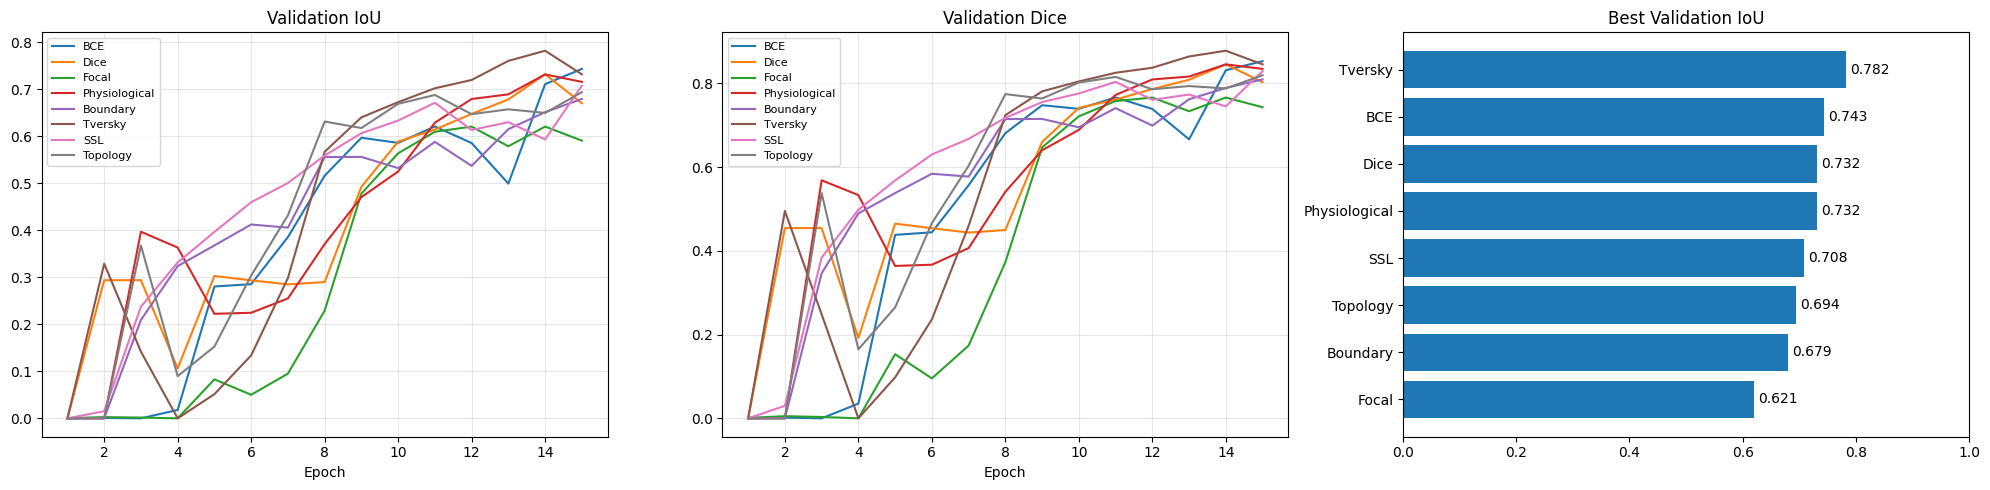

In [134]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for name, h in all_histories.items():
    epochs = np.arange(1, len(h["val_iou"]) + 1)

    axes[0].plot(epochs, h["val_iou"], label=name)
    axes[1].plot(epochs, h["val_dice"], label=name)

axes[0].set_title("Validation IoU")
axes[0].set_xlabel("Epoch")

axes[1].set_title("Validation Dice")
axes[1].set_xlabel("Epoch")

for ax in axes[:2]:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

sorted_df = results_df.sort_values("Best IoU")

bars = axes[2].barh(
    sorted_df["Loss"],
    sorted_df["Best IoU"]
)

axes[2].bar_label(bars, fmt="%.3f", padding=3)
axes[2].set_title("Best Validation IoU")
axes[2].set_xlim(0, 1)

plt.tight_layout()
plt.show()

### Вывод по бонусным функциям потерь

Лучший результат среди восьми экспериментов SegNet показал Tversky Loss — IoU = 0.7820, Dice = 0.8777. Он превзошёл базовые BCE, Dice и Focal Loss.

Tversky также быстро достигает IoU ≥ 0.65 — на 10-й эпохе. Physiological Loss и Structural Similarity Loss показали сопоставимые с базовыми методами результаты, тогда как Boundary и Topological Loss оказались менее эффективными по максимальному IoU.

Topological Loss потребовал значительно больше времени на обучение — около 144 секунд против 77–78 секунд у большинства остальных вариантов.

Таким образом, Tversky Loss оказался наиболее эффективным в данном эксперименте. При этом Physiological и Topological Loss реализованы в адаптированном или упрощённом виде, что необходимо учитывать при сравнении.

## Обучите SegNet на новых лоссах

**Задание**: обучите SegNet на новых лоссах и сравните все три лосса:
*   При каком лоссе модель сходится быстрее?
*   При каком лоссе модель выдает наилучшую метрику?

Напишите развернутый ответ на вопросы.



In [135]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

EPOCHS = 15
LR = 1e-3
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed():
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

loss_functions = {
    "BCE": F.binary_cross_entropy_with_logits,
    "Dice": dice_loss,
    "Focal": lambda logits, labels: focal_loss(labels, logits) / logits.numel()
}

checkpoints_dir = Path("segnet_comparison")
checkpoints_dir.mkdir(exist_ok=True)


In [136]:
histories = {}

for name, loss_fn in loss_functions.items():
    print(f"\n{'=' * 40}")
    print(f"Training SegNet with {name} Loss")
    print(f"{'=' * 40}")

    histories[name] = train_experiment(name, loss_fn)



Training SegNet with BCE Loss


SegNet — BCE:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.6787 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.2s
Epoch 2/15 | Train Loss: 0.6182 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.2s
Epoch 3/15 | Train Loss: 0.4888 | Val IoU: 0.1567 | Val Dice: 0.2710 | Time: 5.2s
Epoch 4/15 | Train Loss: 0.3652 | Val IoU: 0.1213 | Val Dice: 0.2164 | Time: 5.2s
Epoch 5/15 | Train Loss: 0.2719 | Val IoU: 0.2776 | Val Dice: 0.4346 | Time: 5.2s
Epoch 6/15 | Train Loss: 0.2469 | Val IoU: 0.3375 | Val Dice: 0.5046 | Time: 5.2s
Epoch 7/15 | Train Loss: 0.2680 | Val IoU: 0.3797 | Val Dice: 0.5504 | Time: 5.2s
Epoch 8/15 | Train Loss: 0.2201 | Val IoU: 0.4344 | Val Dice: 0.6057 | Time: 5.2s
Epoch 9/15 | Train Loss: 0.1959 | Val IoU: 0.5236 | Val Dice: 0.6873 | Time: 5.2s
Epoch 10/15 | Train Loss: 0.1777 | Val IoU: 0.3862 | Val Dice: 0.5572 | Time: 5.2s
Epoch 11/15 | Train Loss: 0.1793 | Val IoU: 0.6452 | Val Dice: 0.7844 | Time: 5.2s
Epoch 12/15 | Train Loss: 0.1749 | Val IoU: 0.6654 | Val Dice: 0.7991 | Time: 5.2s
Epoch 13/15 |

SegNet — Dice:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.6169 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.2s
Epoch 2/15 | Train Loss: 0.5595 | Val IoU: 0.2414 | Val Dice: 0.3889 | Time: 5.1s
Epoch 3/15 | Train Loss: 0.4488 | Val IoU: 0.0083 | Val Dice: 0.0164 | Time: 5.2s
Epoch 4/15 | Train Loss: 0.3948 | Val IoU: 0.0465 | Val Dice: 0.0889 | Time: 5.1s
Epoch 5/15 | Train Loss: 0.3484 | Val IoU: 0.1944 | Val Dice: 0.3256 | Time: 5.2s
Epoch 6/15 | Train Loss: 0.2827 | Val IoU: 0.1987 | Val Dice: 0.3316 | Time: 5.2s
Epoch 7/15 | Train Loss: 0.2440 | Val IoU: 0.4207 | Val Dice: 0.5923 | Time: 5.2s
Epoch 8/15 | Train Loss: 0.2076 | Val IoU: 0.4536 | Val Dice: 0.6241 | Time: 5.2s
Epoch 9/15 | Train Loss: 0.1812 | Val IoU: 0.5274 | Val Dice: 0.6905 | Time: 5.2s
Epoch 10/15 | Train Loss: 0.1609 | Val IoU: 0.5865 | Val Dice: 0.7393 | Time: 5.2s
Epoch 11/15 | Train Loss: 0.1399 | Val IoU: 0.6440 | Val Dice: 0.7834 | Time: 5.2s
Epoch 12/15 | Train Loss: 0.1283 | Val IoU: 0.6668 | Val Dice: 0.8001 | Time: 5.2s
Epoch 13/15 |

SegNet — Focal:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.1739 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.2s
Epoch 2/15 | Train Loss: 0.1299 | Val IoU: 0.0004 | Val Dice: 0.0008 | Time: 5.2s
Epoch 3/15 | Train Loss: 0.0968 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 5.2s
Epoch 4/15 | Train Loss: 0.0752 | Val IoU: 0.0069 | Val Dice: 0.0137 | Time: 5.2s
Epoch 5/15 | Train Loss: 0.0691 | Val IoU: 0.0163 | Val Dice: 0.0322 | Time: 5.2s
Epoch 6/15 | Train Loss: 0.0656 | Val IoU: 0.2444 | Val Dice: 0.3928 | Time: 5.2s
Epoch 7/15 | Train Loss: 0.0645 | Val IoU: 0.3809 | Val Dice: 0.5517 | Time: 5.2s
Epoch 8/15 | Train Loss: 0.0614 | Val IoU: 0.6160 | Val Dice: 0.7624 | Time: 5.2s
Epoch 9/15 | Train Loss: 0.0590 | Val IoU: 0.4996 | Val Dice: 0.6663 | Time: 5.2s
Epoch 10/15 | Train Loss: 0.0540 | Val IoU: 0.6326 | Val Dice: 0.7750 | Time: 5.2s
Epoch 11/15 | Train Loss: 0.0521 | Val IoU: 0.6339 | Val Dice: 0.7759 | Time: 5.2s
Epoch 12/15 | Train Loss: 0.0508 | Val IoU: 0.6806 | Val Dice: 0.8099 | Time: 5.2s
Epoch 13/15 |

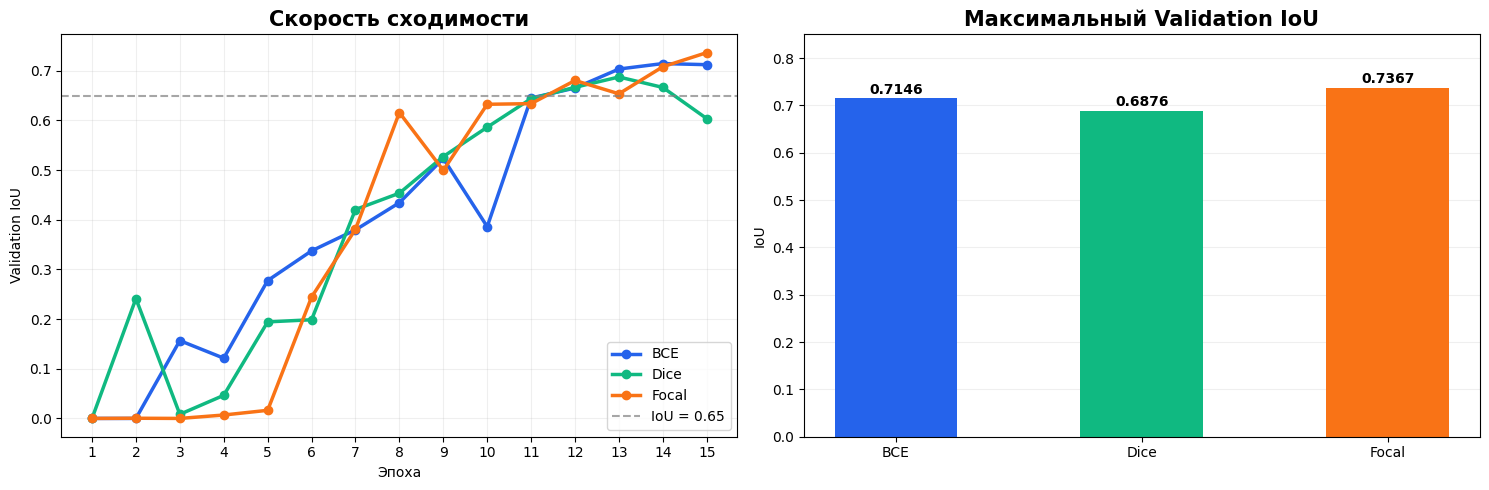

In [137]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

colors = {
    "BCE": "#2563EB",
    "Dice": "#10B981",
    "Focal": "#F97316"
}

ax = axes[0]

for name, h in histories.items():
    epochs = range(1, len(h["val_iou"]) + 1)
    ax.plot(epochs, h["val_iou"], label=name,
            color=colors[name], linewidth=2.5, marker="o")

ax.axhline(0.65, color="gray", linestyle="--",
           alpha=0.7, label="IoU = 0.65")

ax.set_title("Скорость сходимости", fontsize=15, fontweight="bold")
ax.set_xlabel("Эпоха")
ax.set_ylabel("Validation IoU")
ax.set_xticks(range(1, EPOCHS + 1))
ax.legend()
ax.grid(alpha=0.2)

ax = axes[1]

names = list(histories.keys())
scores = [histories[n]["best_iou"] for n in names]

bars = ax.bar(names, scores,
              color=[colors[n] for n in names], width=0.5)

for bar, score in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width() / 2,
            score + 0.01, f"{score:.4f}",
            ha="center", fontweight="bold")

ax.set_title("Максимальный Validation IoU", fontsize=15, fontweight="bold")
ax.set_ylabel("IoU")
ax.set_ylim(0, 0.85)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


1. При каком лоссе модель сходится быстрее?

Все три функции потерь достигают Validation IoU ≥ 0.65 на 12-й эпохе, поэтому однозначного лидера по скорости достижения этого порога нет. При этом дальнейшая динамика обучения отличается.

2. При каком лоссе модель выдаёт наилучшую метрику?

Наилучший результат показал Focal Loss — IoU = 0.7367. BCE Loss достиг 0.7146, а Dice Loss — 0.6876.

Таким образом, в данном эксперименте Focal Loss оказался наиболее эффективным по максимальному IoU. Однако различия зависят от параметров обучения и случайной инициализации модели.

# Задание: Новая модель!

## Модель U-Net [2 балла]

[**U-Net**](https://arxiv.org/abs/1505.04597) — это архитектура нейронной сети, которая получает изображение и выводит его. Первоначально он был задуман для семантической сегментации (как мы ее будем использовать), но он настолько успешен, что с тех пор используется в других контекстах. Получая на вход медицинское изображение, он выведет изображение в оттенках серого, где интенсивность каждого пикселя зависит от вероятности того, что этот пиксель принадлежит интересующей нас области.

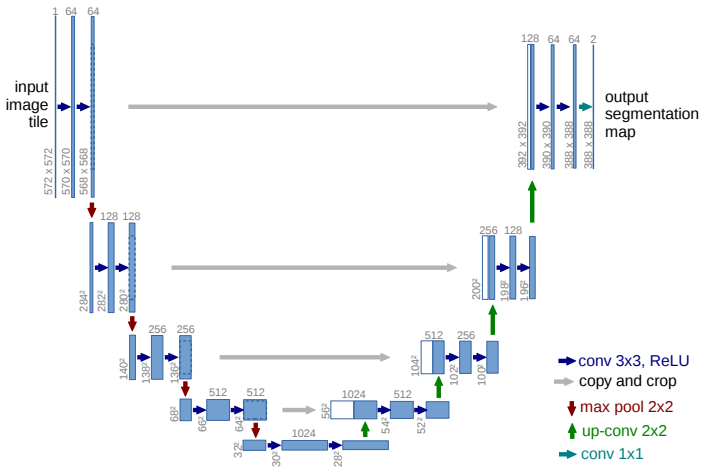

У нас в архитектуре все так же существует энкодер и декодер, как в **SegNet**, но отличительной особеностью данной модели являются *skip-conenctions*, соединяющие части декодера и энкодера. То есть для того чтобы передать на вход декодера тензор, мы конкатенируем симметричный выход с энкодера и выход предыдущего слоя декодера.

* Ronneberger, Olaf, Philipp Fischer, and Thomas Brox. "[U-Net: Convolutional networks for biomedical image segmentation.](https://arxiv.org/pdf/1505.04597.pdf)" International Conference on Medical image computing and computer-assisted intervention. Springer, Cham, 2015.

В оригинальной статье авторы не использовали padding внутри модели (это видно по тому, что размеры карты признаков уменьшаются на 2 каждый раз при движении от слоя к слою). При этом размеры входных изображений авторы единоразово увеличили при помощи mirror padding.

В этом домашнем задании вы можете применить альтернативный подход - сохранять размеры карт признаков при помощью padding = 1 во внутренних слоях.  

In [138]:
import torch.nn.functional as F
import torch.nn as nn

Для реализации UNet вы можете написать классы блоков энкодера и декодера отдельно, как мы сделали при реализации SegNet.

In [139]:
class UNet(nn.Module):
    def __init__(self, n_class=1):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        # Encoder
        self.enc1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.enc2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.enc3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        self.enc4 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(256, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )

        # Decoder
        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = nn.Sequential(
            nn.Conv2d(512, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = nn.Sequential(
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.out_conv = nn.Conv2d(32, n_class, 1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder + skip-connections
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        output = self.out_conv(d1)
        return output


In [140]:
unet_model = UNet().to(device)

## Обучите UNet

Задание: обучите UNet на всех трех лоссах: BCE, Dice, Focal и сравните результаты с SegNet:
*   Какая модель дает лучшие значения по метрике?
*   Какая модель дает лучшие значения по лоссам?
*   Какая модель обучается быстрее?
*   Сравните визуально результаты SegNet и UNet.

Напишите развернутый ответ на вопросы.



In [141]:
unet_histories = {}

for name, loss_fn in loss_functions.items():
    print(f"\nTraining UNet with {name} Loss")

    unet_histories[name] = train_experiment(
        name,
        loss_fn,
        model_class=UNet
    )



Training UNet with BCE Loss


UNet — BCE:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.5973 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 2.5s
Epoch 2/15 | Train Loss: 0.4397 | Val IoU: 0.0027 | Val Dice: 0.0053 | Time: 2.5s
Epoch 3/15 | Train Loss: 0.3822 | Val IoU: 0.3774 | Val Dice: 0.5480 | Time: 2.5s
Epoch 4/15 | Train Loss: 0.3529 | Val IoU: 0.1083 | Val Dice: 0.1955 | Time: 2.5s
Epoch 5/15 | Train Loss: 0.3463 | Val IoU: 0.3618 | Val Dice: 0.5313 | Time: 2.5s
Epoch 6/15 | Train Loss: 0.3141 | Val IoU: 0.4740 | Val Dice: 0.6431 | Time: 2.5s
Epoch 7/15 | Train Loss: 0.2972 | Val IoU: 0.4426 | Val Dice: 0.6136 | Time: 2.5s
Epoch 8/15 | Train Loss: 0.2772 | Val IoU: 0.4562 | Val Dice: 0.6265 | Time: 2.6s
Epoch 9/15 | Train Loss: 0.2790 | Val IoU: 0.6873 | Val Dice: 0.8147 | Time: 2.5s
Epoch 10/15 | Train Loss: 0.2532 | Val IoU: 0.5536 | Val Dice: 0.7126 | Time: 2.5s
Epoch 11/15 | Train Loss: 0.2512 | Val IoU: 0.7193 | Val Dice: 0.8367 | Time: 2.5s
Epoch 12/15 | Train Loss: 0.2341 | Val IoU: 0.7055 | Val Dice: 0.8273 | Time: 2.5s
Epoch 13/15 |

UNet — Dice:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.5045 | Val IoU: 0.0180 | Val Dice: 0.0353 | Time: 2.6s
Epoch 2/15 | Train Loss: 0.3946 | Val IoU: 0.0002 | Val Dice: 0.0004 | Time: 2.6s
Epoch 3/15 | Train Loss: 0.3587 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 2.5s
Epoch 4/15 | Train Loss: 0.3245 | Val IoU: 0.0266 | Val Dice: 0.0518 | Time: 2.5s
Epoch 5/15 | Train Loss: 0.3237 | Val IoU: 0.2044 | Val Dice: 0.3394 | Time: 2.5s
Epoch 6/15 | Train Loss: 0.3009 | Val IoU: 0.4874 | Val Dice: 0.6554 | Time: 2.5s
Epoch 7/15 | Train Loss: 0.2861 | Val IoU: 0.5267 | Val Dice: 0.6900 | Time: 2.5s
Epoch 8/15 | Train Loss: 0.2788 | Val IoU: 0.5837 | Val Dice: 0.7372 | Time: 2.5s
Epoch 9/15 | Train Loss: 0.2727 | Val IoU: 0.6611 | Val Dice: 0.7960 | Time: 2.5s
Epoch 10/15 | Train Loss: 0.2532 | Val IoU: 0.6571 | Val Dice: 0.7931 | Time: 2.5s
Epoch 11/15 | Train Loss: 0.2414 | Val IoU: 0.6966 | Val Dice: 0.8212 | Time: 2.5s
Epoch 12/15 | Train Loss: 0.2269 | Val IoU: 0.7385 | Val Dice: 0.8496 | Time: 2.5s
Epoch 13/15 |

UNet — Focal:   0%|          | 0/15 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 0.1510 | Val IoU: 0.0004 | Val Dice: 0.0007 | Time: 2.6s
Epoch 2/15 | Train Loss: 0.0939 | Val IoU: 0.0000 | Val Dice: 0.0000 | Time: 2.6s
Epoch 3/15 | Train Loss: 0.0762 | Val IoU: 0.0081 | Val Dice: 0.0161 | Time: 2.5s
Epoch 4/15 | Train Loss: 0.0710 | Val IoU: 0.0328 | Val Dice: 0.0635 | Time: 2.5s
Epoch 5/15 | Train Loss: 0.0638 | Val IoU: 0.0291 | Val Dice: 0.0566 | Time: 2.5s
Epoch 6/15 | Train Loss: 0.0574 | Val IoU: 0.2382 | Val Dice: 0.3848 | Time: 2.5s
Epoch 7/15 | Train Loss: 0.0526 | Val IoU: 0.3408 | Val Dice: 0.5084 | Time: 2.6s
Epoch 8/15 | Train Loss: 0.0494 | Val IoU: 0.3247 | Val Dice: 0.4902 | Time: 2.5s
Epoch 9/15 | Train Loss: 0.0535 | Val IoU: 0.5113 | Val Dice: 0.6766 | Time: 2.5s
Epoch 10/15 | Train Loss: 0.0457 | Val IoU: 0.4349 | Val Dice: 0.6061 | Time: 2.5s
Epoch 11/15 | Train Loss: 0.0426 | Val IoU: 0.6598 | Val Dice: 0.7950 | Time: 2.5s
Epoch 12/15 | Train Loss: 0.0391 | Val IoU: 0.7281 | Val Dice: 0.8427 | Time: 2.5s
Epoch 13/15 |

In [142]:
results = []

for model_name, model_histories in {
    "SegNet": histories,
    "UNet": unet_histories
}.items():
    for loss_name, h in model_histories.items():
        results.append({
            "Model": model_name,
            "Loss": loss_name,
            "Best IoU": h["best_iou"],
            "Best Dice": h["val_dice"][h["best_epoch"] - 1],
            "Best Epoch": h["best_epoch"],
            "Val BCE": h["val_bce"][h["best_epoch"] - 1]
        })

df = pd.DataFrame(results)
display(df.sort_values("Best IoU", ascending=False).round(4))


,Model,Loss,Best IoU,Best Dice,Best Epoch,Val BCE
5,UNet,Focal,0.7963,0.8866,13,0.3334
4,UNet,Dice,0.7835,0.8786,13,0.2575
2,SegNet,Focal,0.7367,0.8484,15,0.3186
3,UNet,BCE,0.7315,0.8449,15,0.2797
0,SegNet,BCE,0.7146,0.8336,14,0.2889
1,SegNet,Dice,0.6876,0.8149,13,0.4507


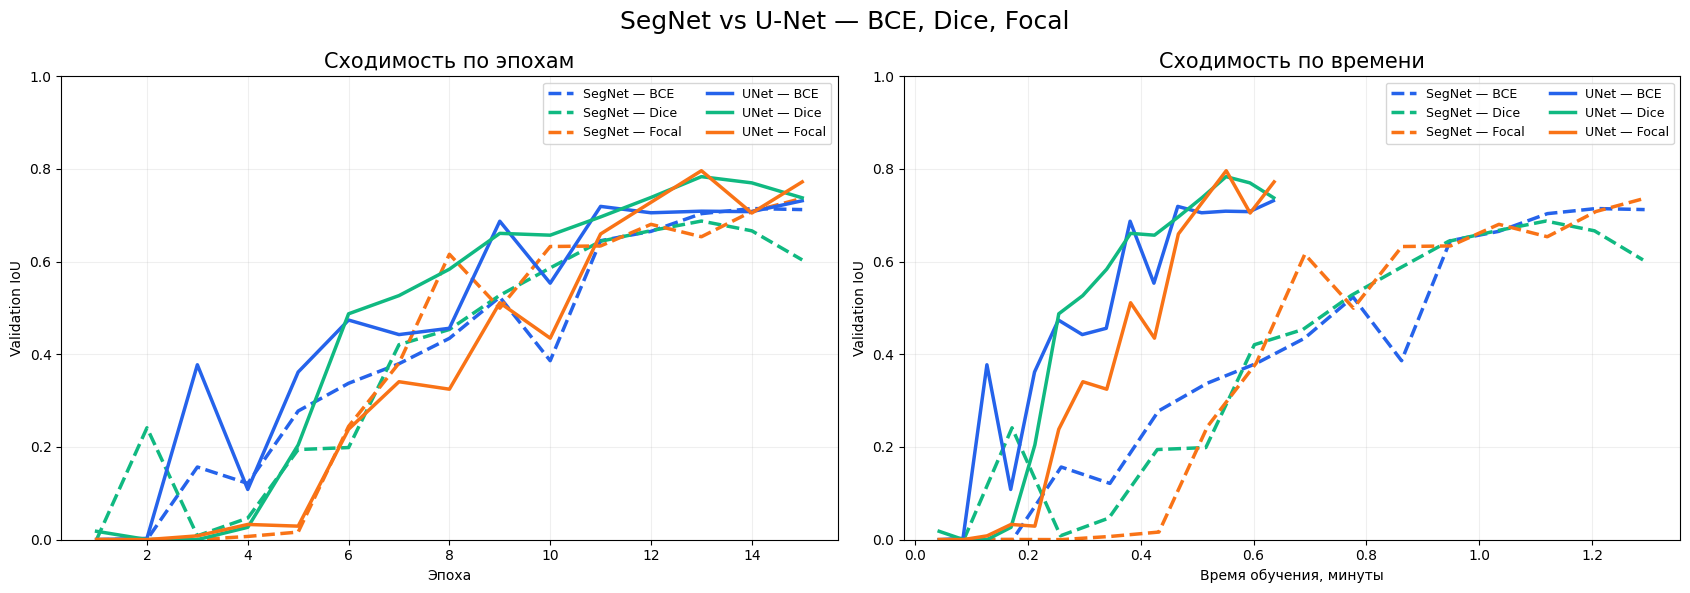

In [143]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

colors = {
    "BCE": "#2563EB",
    "Dice": "#10B981",
    "Focal": "#F97316"
}

all_histories = {
    "SegNet": histories,
    "UNet": unet_histories
}

for model_name, model_histories in all_histories.items():
    for loss_name, h in model_histories.items():
        epochs = np.arange(1, len(h["val_iou"]) + 1)
        elapsed_minutes = np.cumsum(h["epoch_seconds"]) / 60

        style = "-" if model_name == "UNet" else "--"
        label = f"{model_name} — {loss_name}"

        axes[0].plot(
            epochs, h["val_iou"],
            label=label,
            color=colors[loss_name],
            linestyle=style,
            linewidth=2.5
        )

        axes[1].plot(
            elapsed_minutes, h["val_iou"],
            label=label,
            color=colors[loss_name],
            linestyle=style,
            linewidth=2.5
        )

axes[0].set_title("Сходимость по эпохам", fontsize=15)
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Validation IoU")

axes[1].set_title("Сходимость по времени", fontsize=15)
axes[1].set_xlabel("Время обучения, минуты")
axes[1].set_ylabel("Validation IoU")

for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9, ncol=2)
    ax.set_ylim(0, 1)

fig.suptitle("SegNet vs U-Net — BCE, Dice, Focal", fontsize=18)
plt.tight_layout()
plt.show()


### 1. Какая модель даёт лучшие значения по метрике?

Лучший результат показала U-Net с Focal Loss: IoU = 0.7963, Dice = 0.8866. Лучший результат SegNet также получен с Focal Loss: IoU = 0.7367.

В целом U-Net показала более высокое качество сегментации, что может объясняться наличием skip-connections, позволяющих сохранять пространственную информацию.

### 2. Какая модель даёт лучшие значения по лоссам?

Минимальный Validation BCE получила U-Net с Dice Loss — 0.2575. Для сравнения, U-Net с BCE Loss достигла 0.2797, а минимальный результат SegNet составил 0.2889.

U-Net получила меньший Validation BCE при использовании BCE и Dice Loss, однако при Focal Loss показатель SegNet оказался немного лучше.

### 3. Какая модель обучается быстрее?

U-Net обучается примерно в два раза быстрее: около 38 секунд против 77 секунд** у SegNet за 15 эпох.

Кроме того, U-Net с BCE и Dice достигает IoU ≥ 0.65 уже на 9-й эпохе, тогда как все три варианта SegNet достигают этого уровня на 12-й эпохе.

### Общий вывод

В данном эксперименте U-Net в целом оказалась эффективнее SegNet по качеству и скорости обучения. Наилучший IoU обеспечила U-Net с Focal Loss, а минимальный Validation BCE — U-Net с Dice Loss.

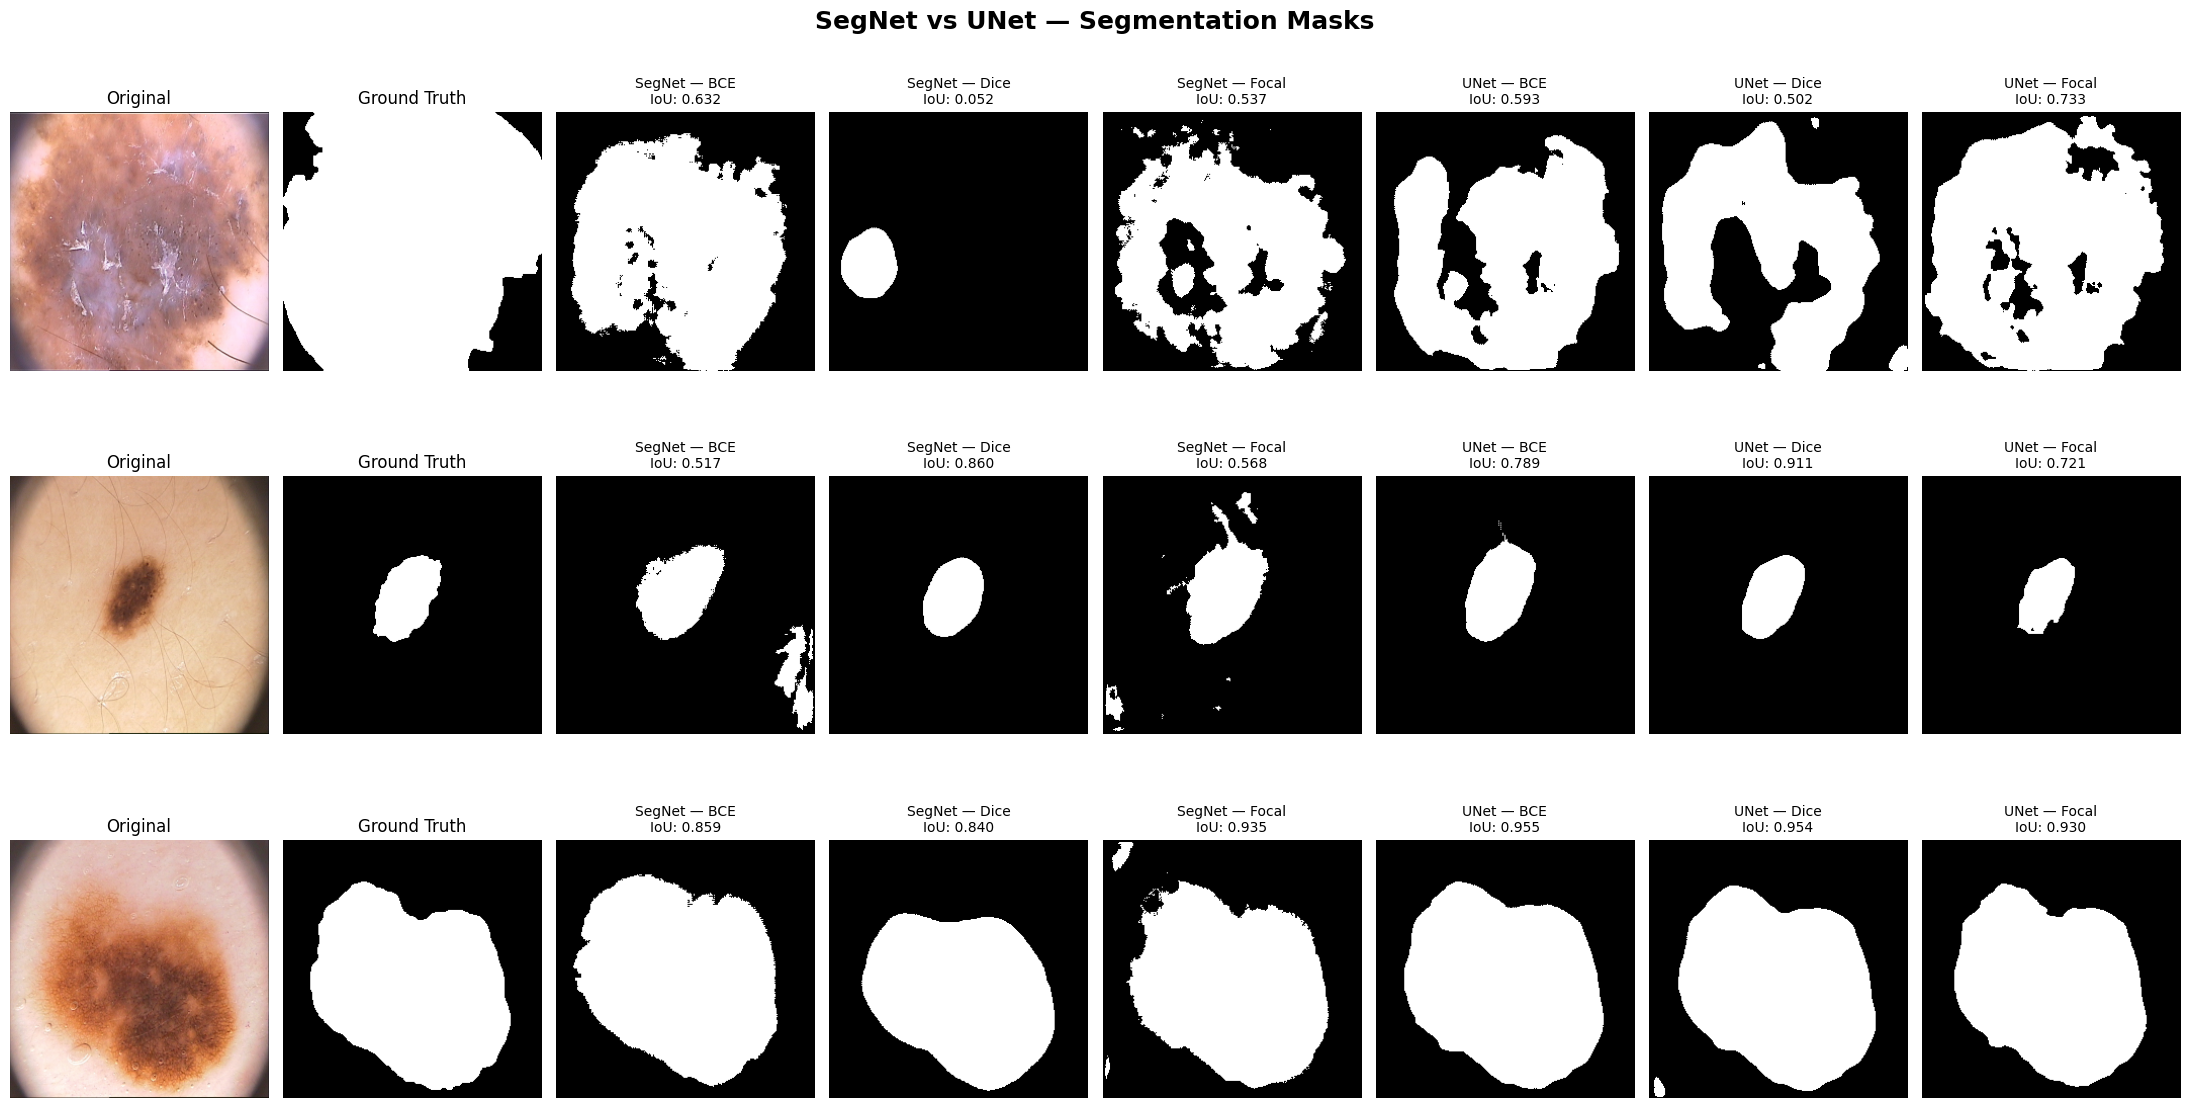

In [144]:
N_SAMPLES = 3
images, masks = next(iter(test_dataloader))

images = images[:N_SAMPLES]
masks = masks[:N_SAMPLES]

models = {
    "SegNet": SegNet,
    "UNet": UNet
}

predictions = {}

for model_name, model_class in models.items():
    for loss_name in ["BCE", "Dice", "Focal"]:
        model = model_class().to(device)

        path = Path("segnet_comparison") / (
            f"{model_name.lower()}_{loss_name.lower()}.pth"
        )

        model.load_state_dict(
            torch.load(path, map_location=device, weights_only=True)
        )
        model.eval()

        with torch.no_grad():
            logits = model(images.to(device).float())
            preds = (torch.sigmoid(logits) >= 0.5)
            predictions[(model_name, loss_name)] = preds.cpu().numpy()

        del model

fig, axes = plt.subplots(N_SAMPLES, 8, figsize=(22, 4 * N_SAMPLES),
                         squeeze=False)

model_keys = list(predictions.keys())

for i in range(N_SAMPLES):
    image = images[i].permute(1, 2, 0).numpy()
    target = masks[i, 0].numpy() > 0.5

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original")

    axes[i, 1].imshow(target, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground Truth")

    for j, (model_name, loss_name) in enumerate(model_keys, start=2):
        pred = predictions[(model_name, loss_name)][i, 0]

        intersection = np.logical_and(pred, target).sum()
        union = np.logical_or(pred, target).sum()
        iou = (intersection + 1e-8) / (union + 1e-8)

        axes[i, j].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_title(
            f"{model_name} — {loss_name}\nIoU: {iou:.3f}",
            fontsize=10
        )

    for ax in axes[i]:
        ax.axis("off")

fig.suptitle("SegNet vs UNet — Segmentation Masks",
             fontsize=18, fontweight="bold")

plt.tight_layout()
plt.savefig("segmentation_masks_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()

### 4. Визуальное сравнение результатов SegNet и U-Net

По визуальным результатам **U-Net точнее воспроизводит форму и границы объектов**, формируя более гладкие и целостные маски с меньшим количеством ошибок.

Особенно заметна разница на первом и третьем изображениях, где SegNet допускает пропуски, шумы и ложные срабатывания. U-Net лучше сохраняет структуру объектов, что, вероятно, связано с использованием skip-connections.

**Таким образом, U-Net показывает более качественную сегментацию на рассмотренных изображениях**, что согласуется с полученными значениями IoU.